# Chapter 17: Sequence-to-Sequence Architectures: Encoder-Decoders and Decoders
Character-level encoder-decoder translator


Programs from the book: [_Python for Natural Language Processing_](https://link.springer.com/book/9783031575488)

__Author__: Pierre Nugues

## Download the data

Have a look at the http://www.manythings.org/anki/ site and select a corpus with at least 10,000 pairs. You should understand the target language well. Ideally, it should be your mother tongue.
Then uncomment and run the lines below.

In [71]:
#!curl -O http://www.manythings.org/anki/fra-eng.zip
#!unzip fra-eng.zip
#!mkdir ../datasets/tatoeba
#!mv fra.txt ../datasets/tatoeba
#!rm fra-eng.zip _about.txt

In [72]:
import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'

## Modules

In [73]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from torch.optim.lr_scheduler import LambdaLR

from torcheval.metrics.functional import bleu_score

import random
import numpy as np
import math
import regex as re

import matplotlib.pyplot as plt
from tqdm import tqdm
import json

In [74]:
random.seed(1234)
np.random.seed(1234)
torch.manual_seed(1234)

In [75]:
num_samples = 237000 #100000  # Number of samples to train on.
max_len = 120  # max number of characters per sentence

In [76]:
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
DEVICE = torch.device(device)
DEVICE

device(type='cpu')

## Dataset

### Creating the pairs

In [77]:
PATH = 'tatoeba/'

In [78]:
data_file = PATH + 'kan.txt'

In [79]:
with open(data_file, 'r', encoding='utf-8') as f:
    lines = f.read().strip().split('\n')

In [80]:
len(lines)

160

In [81]:
num_samples = min(num_samples, len(lines))
num_samples

160

In [82]:
interval = 3
ran = round(random.random()*(num_samples-interval))
lines[ran:ran+interval]

['In order to stay awake, I may have to drink more coffee.\tಎಚ್ಚರವಾಗಿರಲು ನಾನು ಇನ್ನು ಸ್ವಲ್ಪ ಕಾಫಿ ಕುಡಿಯಬೇಕು ಅಂತ ಅನಿಸುತ್ತೆ.\tCC-BY 2.0 (France) Attribution: tatoeba.org #322719 (CK) & #4776791 (legalghost)',
 'The only time you talk to me is when you need some money.\tಯಾವಾಗ ನಿನಗೆ ದುಡ್ಡು ಬೇಕಾದರೆ ಮಾತ್ರ ನೀನು ನನ್ನ ಜೊತೆ ಮಾತನಾಡುತ್ತೇಯ.\tCC-BY 2.0 (France) Attribution: tatoeba.org #2042689 (CK) & #4774595 (legalghost)',
 'Go to the wine cellar and get a couple of bottles of wine.\tಸರಾಯಿ ನೆಲಮಾಳಿಗೆಗೆ ಹೋಗಿ ಎರಡು ಬಾಟಲಿ ವೈನು ತೆಗೆದುಕೊಂಡು ಬನ್ನಿ.\tCC-BY 2.0 (France) Attribution: tatoeba.org #1860710 (CK) & #4775411 (legalghost)']

In [83]:
#lines = lines[:num_samples]

In [84]:
def create_pairs(lines, max_len, num_samples, shuffle=True, anki=True):
    src_seqs = []
    tgt_seqs = []
    lowest_id = 100000000000
    sentence = ()
    if shuffle:
        random.shuffle(lines)
    for line in lines:
        src_seq, tgt_seq, attri = line.split('\t')
        ids = [int(d[1:]) for d in re.findall(r"#\d+", attri)]
        # print(ids)
        for id in ids :
            if lowest_id > id :
                lowest_id = id
                sentence = src_seq,tgt_seq
        if len(src_seq) <= max_len and len(tgt_seq) <= max_len:
            src_seqs.append(src_seq)
            tgt_seqs.append(tgt_seq)
    # print(lowest_id, sentence)
    return src_seqs[:num_samples], tgt_seqs[:num_samples]

In [85]:
tgt_seqs, src_seqs = create_pairs(lines, max_len, num_samples)

In [86]:
len(src_seqs)

160

In [87]:
src_seqs[5]

'ಆ ಗಾಯ ಹೇಗೆ ಸಿಕ್ಕಿತು?'

In [88]:
tgt_seqs[5]

'How did you get that scar?'

In [89]:
max(map(len, src_seqs)), max(map(len, tgt_seqs))

(66, 63)

### Train/Validation

Percentage train/validation

In [90]:
TRAIN_PERCENTAGE = 0.8
train_val = int(TRAIN_PERCENTAGE * num_samples)
train_val

128

We split the lists

In [91]:
train_src_seqs = src_seqs[:train_val]
train_tgt_seqs = tgt_seqs[:train_val]

val_src_seqs = src_seqs[train_val:]
val_tgt_seqs = tgt_seqs[train_val:]

### The input and output symbols: Characters
The language pair shares the same vocabulary as in _Attention Is All You Need_

In [92]:
src_chars = set(''.join(src_seqs)) # Remove "train_" to make the charcterset correct
tgt_chars = set(''.join(tgt_seqs)) # Remove "train_" to make the charcterset correct
charset = sorted(
    list(set.union(src_chars,
                   tgt_chars)))
charset

[' ',
 "'",
 '(',
 ')',
 ',',
 '.',
 '0',
 '1',
 '2',
 '3',
 '5',
 '8',
 ':',
 '?',
 'A',
 'B',
 'C',
 'D',
 'E',
 'F',
 'G',
 'H',
 'I',
 'J',
 'L',
 'M',
 'N',
 'O',
 'P',
 'S',
 'T',
 'W',
 'Y',
 'Z',
 'a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z',
 'ಂ',
 'ಃ',
 'ಅ',
 'ಆ',
 'ಇ',
 'ಈ',
 'ಉ',
 'ಎ',
 'ಏ',
 'ಐ',
 'ಒ',
 'ಓ',
 'ಕ',
 'ಖ',
 'ಗ',
 'ಘ',
 'ಚ',
 'ಛ',
 'ಜ',
 'ಝ',
 'ಟ',
 'ಠ',
 'ಡ',
 'ಣ',
 'ತ',
 'ಥ',
 'ದ',
 'ಧ',
 'ನ',
 'ಪ',
 'ಫ',
 'ಬ',
 'ಭ',
 'ಮ',
 'ಯ',
 'ರ',
 'ಲ',
 'ಳ',
 'ವ',
 'ಶ',
 'ಷ',
 'ಸ',
 'ಹ',
 'ಾ',
 'ಿ',
 'ೀ',
 'ು',
 'ೂ',
 'ೃ',
 'ೆ',
 'ೇ',
 'ೈ',
 'ೊ',
 'ೋ',
 'ೌ',
 '್',
 '೦',
 '೨',
 '೩']

In [93]:
len(charset)

118

### Special symbols

In [94]:
# Make sure the tokens are in order of their indices to properly insert them in vocab
special_tokens = ['<pad>', '<unk>', '<s>', '</s>']

In [95]:
charset = special_tokens + charset

In [96]:
idx2token = dict(enumerate(charset))
idx2token

{0: '<pad>',
 1: '<unk>',
 2: '<s>',
 3: '</s>',
 4: ' ',
 5: "'",
 6: '(',
 7: ')',
 8: ',',
 9: '.',
 10: '0',
 11: '1',
 12: '2',
 13: '3',
 14: '5',
 15: '8',
 16: ':',
 17: '?',
 18: 'A',
 19: 'B',
 20: 'C',
 21: 'D',
 22: 'E',
 23: 'F',
 24: 'G',
 25: 'H',
 26: 'I',
 27: 'J',
 28: 'L',
 29: 'M',
 30: 'N',
 31: 'O',
 32: 'P',
 33: 'S',
 34: 'T',
 35: 'W',
 36: 'Y',
 37: 'Z',
 38: 'a',
 39: 'b',
 40: 'c',
 41: 'd',
 42: 'e',
 43: 'f',
 44: 'g',
 45: 'h',
 46: 'i',
 47: 'j',
 48: 'k',
 49: 'l',
 50: 'm',
 51: 'n',
 52: 'o',
 53: 'p',
 54: 'r',
 55: 's',
 56: 't',
 57: 'u',
 58: 'v',
 59: 'w',
 60: 'x',
 61: 'y',
 62: 'z',
 63: 'ಂ',
 64: 'ಃ',
 65: 'ಅ',
 66: 'ಆ',
 67: 'ಇ',
 68: 'ಈ',
 69: 'ಉ',
 70: 'ಎ',
 71: 'ಏ',
 72: 'ಐ',
 73: 'ಒ',
 74: 'ಓ',
 75: 'ಕ',
 76: 'ಖ',
 77: 'ಗ',
 78: 'ಘ',
 79: 'ಚ',
 80: 'ಛ',
 81: 'ಜ',
 82: 'ಝ',
 83: 'ಟ',
 84: 'ಠ',
 85: 'ಡ',
 86: 'ಣ',
 87: 'ತ',
 88: 'ಥ',
 89: 'ದ',
 90: 'ಧ',
 91: 'ನ',
 92: 'ಪ',
 93: 'ಫ',
 94: 'ಬ',
 95: 'ಭ',
 96: 'ಮ',
 97: 'ಯ',
 98: 'ರ',
 99: 'ಲ

In [97]:
token2idx = {char: idx for idx, char
             in idx2token.items()}
token2idx

{'<pad>': 0,
 '<unk>': 1,
 '<s>': 2,
 '</s>': 3,
 ' ': 4,
 "'": 5,
 '(': 6,
 ')': 7,
 ',': 8,
 '.': 9,
 '0': 10,
 '1': 11,
 '2': 12,
 '3': 13,
 '5': 14,
 '8': 15,
 ':': 16,
 '?': 17,
 'A': 18,
 'B': 19,
 'C': 20,
 'D': 21,
 'E': 22,
 'F': 23,
 'G': 24,
 'H': 25,
 'I': 26,
 'J': 27,
 'L': 28,
 'M': 29,
 'N': 30,
 'O': 31,
 'P': 32,
 'S': 33,
 'T': 34,
 'W': 35,
 'Y': 36,
 'Z': 37,
 'a': 38,
 'b': 39,
 'c': 40,
 'd': 41,
 'e': 42,
 'f': 43,
 'g': 44,
 'h': 45,
 'i': 46,
 'j': 47,
 'k': 48,
 'l': 49,
 'm': 50,
 'n': 51,
 'o': 52,
 'p': 53,
 'r': 54,
 's': 55,
 't': 56,
 'u': 57,
 'v': 58,
 'w': 59,
 'x': 60,
 'y': 61,
 'z': 62,
 'ಂ': 63,
 'ಃ': 64,
 'ಅ': 65,
 'ಆ': 66,
 'ಇ': 67,
 'ಈ': 68,
 'ಉ': 69,
 'ಎ': 70,
 'ಏ': 71,
 'ಐ': 72,
 'ಒ': 73,
 'ಓ': 74,
 'ಕ': 75,
 'ಖ': 76,
 'ಗ': 77,
 'ಘ': 78,
 'ಚ': 79,
 'ಛ': 80,
 'ಜ': 81,
 'ಝ': 82,
 'ಟ': 83,
 'ಠ': 84,
 'ಡ': 85,
 'ಣ': 86,
 'ತ': 87,
 'ಥ': 88,
 'ದ': 89,
 'ಧ': 90,
 'ನ': 91,
 'ಪ': 92,
 'ಫ': 93,
 'ಬ': 94,
 'ಭ': 95,
 'ಮ': 96,
 'ಯ': 97,
 'ರ': 98,
 'ಲ': 9

In [98]:
len(idx2token)

122

### Text Encoding

In [99]:
def seqs2tensors(seqs, token2idx):
    tensors = []
    for seq in seqs:
        seq = ['<s>'] + list(seq) + ['</s>']
        tensors += [torch.LongTensor(
            [token2idx.get(x, 1) for x in seq])]  # <unk> -> 1
    return tensors

In [100]:
train_src_seqs[:2]

['ಟಾಮ್ ಮೇರಿ ಮೇಲೆ ಪ್ರೀತಿ ಇದ್ಯಾ?', 'ನೀವು ಪತ್ರಿಕೆಯನ್ನು ಓದಿ ಮುಗಿಸಿದ್ದೀರಾ?']

In [101]:
train_tgt_seqs[:2]

['Does Tom have a crush on Mary?', 'Are you finished reading the paper?']

In [102]:
seqs2tensors(train_tgt_seqs[:2], token2idx)

[tensor([ 2, 21, 52, 42, 55,  4, 34, 52, 50,  4, 45, 38, 58, 42,  4, 38,  4, 40,
         54, 57, 55, 45,  4, 52, 51,  4, 29, 38, 54, 61, 17,  3]),
 tensor([ 2, 18, 54, 42,  4, 61, 52, 57,  4, 43, 46, 51, 46, 55, 45, 42, 41,  4,
         54, 42, 38, 41, 46, 51, 44,  4, 56, 45, 42,  4, 53, 38, 53, 42, 54, 17,
          3])]

In [103]:
seqs2tensors(train_tgt_seqs, token2idx)[:3]

[tensor([ 2, 21, 52, 42, 55,  4, 34, 52, 50,  4, 45, 38, 58, 42,  4, 38,  4, 40,
         54, 57, 55, 45,  4, 52, 51,  4, 29, 38, 54, 61, 17,  3]),
 tensor([ 2, 18, 54, 42,  4, 61, 52, 57,  4, 43, 46, 51, 46, 55, 45, 42, 41,  4,
         54, 42, 38, 41, 46, 51, 44,  4, 56, 45, 42,  4, 53, 38, 53, 42, 54, 17,
          3]),
 tensor([ 2, 36, 52, 57,  4, 45, 38, 58, 42,  4, 56, 52,  4, 56, 42, 49, 49,  4,
         50, 42,  4, 42, 60, 38, 40, 56, 49, 61,  4, 59, 45, 38, 56,  4, 26,  4,
         51, 42, 42, 41,  4, 56, 52,  4, 41, 52,  9,  3])]

In [104]:
def tensors2seqs(tensors, idx2token):
    seqs = []
    for tensor in tensors:
        seqs += [[idx2token.get(x.item(), '<unk>') for x in tensor]]
    return seqs

In [105]:
tensors2seqs(seqs2tensors(train_src_seqs, token2idx)[:3], idx2token)

[['<s>',
  'ಟ',
  'ಾ',
  'ಮ',
  '್',
  ' ',
  'ಮ',
  'ೇ',
  'ರ',
  'ಿ',
  ' ',
  'ಮ',
  'ೇ',
  'ಲ',
  'ೆ',
  ' ',
  'ಪ',
  '್',
  'ರ',
  'ೀ',
  'ತ',
  'ಿ',
  ' ',
  'ಇ',
  'ದ',
  '್',
  'ಯ',
  'ಾ',
  '?',
  '</s>'],
 ['<s>',
  'ನ',
  'ೀ',
  'ವ',
  'ು',
  ' ',
  'ಪ',
  'ತ',
  '್',
  'ರ',
  'ಿ',
  'ಕ',
  'ೆ',
  'ಯ',
  'ನ',
  '್',
  'ನ',
  'ು',
  ' ',
  'ಓ',
  'ದ',
  'ಿ',
  ' ',
  'ಮ',
  'ು',
  'ಗ',
  'ಿ',
  'ಸ',
  'ಿ',
  'ದ',
  '್',
  'ದ',
  'ೀ',
  'ರ',
  'ಾ',
  '?',
  '</s>'],
 ['<s>',
  'ನ',
  'ಾ',
  'ನ',
  'ು',
  ' ',
  'ಏ',
  'ನ',
  'ನ',
  '್',
  'ನ',
  'ು',
  ' ',
  'ಮ',
  'ಾ',
  'ಡ',
  'ಬ',
  'ೇ',
  'ಕ',
  'ೆ',
  'ಂ',
  'ದ',
  'ು',
  ' ',
  'ಸ',
  'ರ',
  'ಿ',
  'ಯ',
  'ಾ',
  'ಗ',
  'ಿ',
  ' ',
  'ನ',
  'ೀ',
  'ವ',
  'ು',
  ' ',
  'ಹ',
  'ೇ',
  'ಳ',
  'ಬ',
  'ೇ',
  'ಕ',
  'ು',
  '.',
  '</s>']]

## Model

In [106]:
class Embedding(nn.Module):
    def __init__(self,
                 vocab_size,
                 d_model,
                 dropout=0.1,
                 max_len=max_len):
        super().__init__()
        self.d_model = d_model
        self.max_len = max_len
        self.input_embedding = nn.Embedding(vocab_size, d_model,
                                            padding_idx=0)
        pe = self.pos_encoding(max_len, d_model)
        self.pos_embedding = nn.Embedding.from_pretrained(
            pe, freeze=True)
        self.dropout = nn.Dropout(dropout)

    def forward(self, X):
        pos_mat = torch.arange(X.size(dim=-1), device=X.device)
        X = self.input_embedding(X) * math.sqrt(self.d_model)
        X += self.pos_embedding(pos_mat)
        return self.dropout(X)

    def pos_encoding(self, max_len, d_model):
        dividend = torch.arange(max_len).unsqueeze(0).T
        divisor = torch.pow(10000.0,
                            torch.arange(0, d_model, 2)/d_model)
        angles = dividend / divisor
        pe = torch.zeros((max_len, d_model))
        pe[:, 0::2] = torch.sin(angles)
        pe[:, 1::2] = torch.cos(angles)
        return pe

In [107]:
embeddings = Embedding(5, 10, dropout=0.0)

In [108]:
embeddings

Embedding(
  (input_embedding): Embedding(5, 10, padding_idx=0)
  (pos_embedding): Embedding(120, 10)
  (dropout): Dropout(p=0.0, inplace=False)
)

In [109]:
class Translator(nn.Module):
    def __init__(self,
                 d_model=512,
                 nhead=8,
                 num_encoder_layers=6,
                 num_decoder_layers=6,
                 dim_feedforward=2048,  # 4 x d_model
                 dropout=0.1,
                 vocab_size=30000,
                 max_len=128):
        super().__init__()
        self.embedding = Embedding(vocab_size,
                                   d_model,
                                   max_len=max_len)
        self.transformer = nn.Transformer(
            d_model,
            nhead,
            num_encoder_layers,
            num_decoder_layers,
            dim_feedforward,
            dropout,
            batch_first=True)
        self.fc = nn.Linear(d_model, vocab_size)
        self.fc.weight = \
            self.embedding.input_embedding.weight

    def forward(self, src, tgt,
                src_padding, tgt_padding):
        src_embs = self.embedding(src)
        tgt_embs = self.embedding(tgt)
        tgt_mask = \
            nn.Transformer.generate_square_subsequent_mask(
                tgt.size(dim=1), device=DEVICE)
        x = self.transformer(
            src_embs,
            tgt_embs,
            tgt_mask=tgt_mask,
            src_key_padding_mask=src_padding,
            memory_key_padding_mask=src_padding,
            tgt_key_padding_mask=tgt_padding)
        return self.fc(x)

In [110]:
translator = Translator(vocab_size=len(idx2token)).to(DEVICE)

In [111]:
src_batch = pad_sequence(seqs2tensors(
    train_src_seqs[:32], token2idx),
    batch_first=True, padding_value=0).to(DEVICE)
tgt_batch = pad_sequence(seqs2tensors(
    train_tgt_seqs[:32], token2idx),
    batch_first=True, padding_value=0).to(DEVICE)

In [112]:
translator.eval()
translator(src_batch, tgt_batch, None, None).size()

torch.Size([32, 61, 122])

In [113]:
src_padding_mask = (src_batch == 0)
tgt_padding_mask = (tgt_batch == 0).float()

In [114]:
src_padding_mask = src_padding_mask.to(DEVICE)
src_padding_mask

tensor([[False, False, False,  ...,  True,  True,  True],
        [False, False, False,  ...,  True,  True,  True],
        [False, False, False,  ...,  True,  True,  True],
        ...,
        [False, False, False,  ...,  True,  True,  True],
        [False, False, False,  ...,  True,  True,  True],
        [False, False, False,  ...,  True,  True,  True]])

In [115]:
tgt_padding_mask = tgt_padding_mask.to(DEVICE)
tgt_padding_mask

tensor([[0., 0., 0.,  ..., 1., 1., 1.],
        [0., 0., 0.,  ..., 1., 1., 1.],
        [0., 0., 0.,  ..., 1., 1., 1.],
        ...,
        [0., 0., 0.,  ..., 1., 1., 1.],
        [0., 0., 0.,  ..., 1., 1., 1.],
        [0., 0., 0.,  ..., 1., 1., 1.]])

In [116]:
translator(src_batch, tgt_batch,
           src_padding_mask, tgt_padding_mask).size()

torch.Size([32, 61, 122])

In [117]:
tensors2seqs(
    torch.argmax(
        translator(src_batch, tgt_batch,
                   src_padding_mask, tgt_padding_mask),
        dim=-1),
    idx2token)

[['೨',
  '೨',
  '೨',
  '೨',
  '೨',
  '೨',
  'ಎ',
  '೨',
  'ಎ',
  '೨',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  '೨',
  'ಎ',
  '೨',
  'ಉ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  '೨',
  'ಎ',
  'ಎ',
  '೨',
  '೨',
  'a',
  'ಎ',
  'ಎ',
  'ಎ',
  '೨',
  '೨',
  'ಎ',
  '೨',
  '೨',
  '೨',
  '೨',
  '೨',
  '೨',
  '೨',
  '೨',
  '೨',
  '೨',
  '೨',
  '೨',
  '೨',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  '೨'],
 ['<s>',
  'ಎ',
  'r',
  'a',
  'ಎ',
  '೨',
  'ಎ',
  'ಎ',
  'ಎ',
  'f',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'r',
  'ಎ',
  'ಎ',
  'ಎ',
  'r',
  'ಎ',
  'a',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'a',
  'ಎ',
  'ಎ',
  'ಎ',
  'a',
  'ಎ',
  'a',
  'ಎ',
  'ಎ',
  'r',
  'ಎ',
  'a',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ'],
 ['ಎ',
  'Y',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'a',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  'ಎ',
  

## Model Creation

In [118]:
token2idx

{'<pad>': 0,
 '<unk>': 1,
 '<s>': 2,
 '</s>': 3,
 ' ': 4,
 "'": 5,
 '(': 6,
 ')': 7,
 ',': 8,
 '.': 9,
 '0': 10,
 '1': 11,
 '2': 12,
 '3': 13,
 '5': 14,
 '8': 15,
 ':': 16,
 '?': 17,
 'A': 18,
 'B': 19,
 'C': 20,
 'D': 21,
 'E': 22,
 'F': 23,
 'G': 24,
 'H': 25,
 'I': 26,
 'J': 27,
 'L': 28,
 'M': 29,
 'N': 30,
 'O': 31,
 'P': 32,
 'S': 33,
 'T': 34,
 'W': 35,
 'Y': 36,
 'Z': 37,
 'a': 38,
 'b': 39,
 'c': 40,
 'd': 41,
 'e': 42,
 'f': 43,
 'g': 44,
 'h': 45,
 'i': 46,
 'j': 47,
 'k': 48,
 'l': 49,
 'm': 50,
 'n': 51,
 'o': 52,
 'p': 53,
 'r': 54,
 's': 55,
 't': 56,
 'u': 57,
 'v': 58,
 'w': 59,
 'x': 60,
 'y': 61,
 'z': 62,
 'ಂ': 63,
 'ಃ': 64,
 'ಅ': 65,
 'ಆ': 66,
 'ಇ': 67,
 'ಈ': 68,
 'ಉ': 69,
 'ಎ': 70,
 'ಏ': 71,
 'ಐ': 72,
 'ಒ': 73,
 'ಓ': 74,
 'ಕ': 75,
 'ಖ': 76,
 'ಗ': 77,
 'ಘ': 78,
 'ಚ': 79,
 'ಛ': 80,
 'ಜ': 81,
 'ಝ': 82,
 'ಟ': 83,
 'ಠ': 84,
 'ಡ': 85,
 'ಣ': 86,
 'ತ': 87,
 'ಥ': 88,
 'ದ': 89,
 'ಧ': 90,
 'ನ': 91,
 'ಪ': 92,
 'ಫ': 93,
 'ಬ': 94,
 'ಭ': 95,
 'ಮ': 96,
 'ಯ': 97,
 'ರ': 98,
 'ಲ': 9

In [119]:
VOCAB_SIZE = len(token2idx)
D_MODEL = 512
NHEAD = 8
DIM_FF = 4 * D_MODEL
BATCH_SIZE = 32
NUM_ENCODER_LAYERS = 3
NUM_DECODER_LAYERS = 3
MAX_LEN = max_len + 2  # start and end
WARMUP_STEPS = 4000
MODEL_NAME = 'pico_model.pth'

In [120]:
token2idx

{'<pad>': 0,
 '<unk>': 1,
 '<s>': 2,
 '</s>': 3,
 ' ': 4,
 "'": 5,
 '(': 6,
 ')': 7,
 ',': 8,
 '.': 9,
 '0': 10,
 '1': 11,
 '2': 12,
 '3': 13,
 '5': 14,
 '8': 15,
 ':': 16,
 '?': 17,
 'A': 18,
 'B': 19,
 'C': 20,
 'D': 21,
 'E': 22,
 'F': 23,
 'G': 24,
 'H': 25,
 'I': 26,
 'J': 27,
 'L': 28,
 'M': 29,
 'N': 30,
 'O': 31,
 'P': 32,
 'S': 33,
 'T': 34,
 'W': 35,
 'Y': 36,
 'Z': 37,
 'a': 38,
 'b': 39,
 'c': 40,
 'd': 41,
 'e': 42,
 'f': 43,
 'g': 44,
 'h': 45,
 'i': 46,
 'j': 47,
 'k': 48,
 'l': 49,
 'm': 50,
 'n': 51,
 'o': 52,
 'p': 53,
 'r': 54,
 's': 55,
 't': 56,
 'u': 57,
 'v': 58,
 'w': 59,
 'x': 60,
 'y': 61,
 'z': 62,
 'ಂ': 63,
 'ಃ': 64,
 'ಅ': 65,
 'ಆ': 66,
 'ಇ': 67,
 'ಈ': 68,
 'ಉ': 69,
 'ಎ': 70,
 'ಏ': 71,
 'ಐ': 72,
 'ಒ': 73,
 'ಓ': 74,
 'ಕ': 75,
 'ಖ': 76,
 'ಗ': 77,
 'ಘ': 78,
 'ಚ': 79,
 'ಛ': 80,
 'ಜ': 81,
 'ಝ': 82,
 'ಟ': 83,
 'ಠ': 84,
 'ಡ': 85,
 'ಣ': 86,
 'ತ': 87,
 'ಥ': 88,
 'ದ': 89,
 'ಧ': 90,
 'ನ': 91,
 'ಪ': 92,
 'ಫ': 93,
 'ಬ': 94,
 'ಭ': 95,
 'ಮ': 96,
 'ಯ': 97,
 'ರ': 98,
 'ಲ': 9

In [121]:
translator = Translator(d_model=D_MODEL,
                        nhead=NHEAD,
                        num_decoder_layers=NUM_ENCODER_LAYERS,
                        num_encoder_layers=NUM_DECODER_LAYERS,
                        dim_feedforward=DIM_FF,
                        vocab_size=VOCAB_SIZE,
                        max_len=MAX_LEN)

In [122]:
translator

Translator(
  (embedding): Embedding(
    (input_embedding): Embedding(122, 512, padding_idx=0)
    (pos_embedding): Embedding(122, 512)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-2): 3 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
          )
          (linear1): Linear(in_features=512, out_features=2048, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=2048, out_features=512, bias=True)
          (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.1, inplace=False)
          (dropout2): Dropout(p=0.1, inplace=False)
        )
      )
      (norm): LayerNorm((512,), eps=1e-05, elementw

In [123]:
for p in translator.parameters():
    if p.requires_grad and p.dim() > 1:
        nn.init.xavier_uniform_(p)

In [124]:
loss_fn = torch.nn.CrossEntropyLoss(label_smoothing=0.1, ignore_index=0)

We set the learning rate to 1 as we will use a scheduler. Otherwise `lr=0.0001`

In [125]:
optimizer = torch.optim.Adam(
    translator.parameters(), lr=1, betas=(0.9, 0.98),
    eps=1e-9)
"""optimizer = torch.optim.NAdam(translator.parameters())"""

'optimizer = torch.optim.NAdam(translator.parameters())'

## Warmup Steps

We use the definition from Vaswani and a possible scaling factor

In [126]:
def learning_rate(step_num, d_model, factor, warmup_steps):
    if step_num == 0:
        step_num = 1
    return factor * (
        d_model ** (-0.5) * min(step_num * warmup_steps **
                                (-1.5), step_num ** (-0.5))
    )

In [127]:
lr_scheduler = LambdaLR(
    optimizer=optimizer,
    lr_lambda=lambda step_num: learning_rate(
        step_num, d_model=D_MODEL, factor=1.0, warmup_steps=WARMUP_STEPS
    ),
)

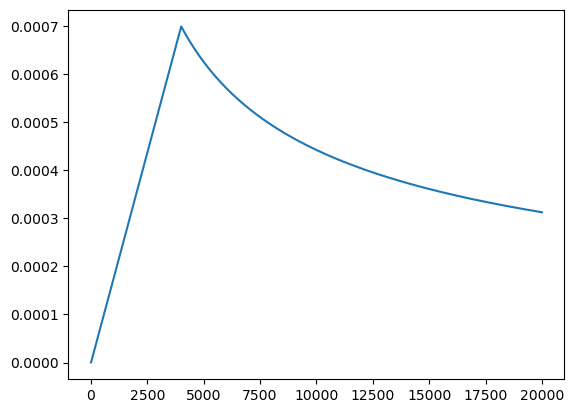

In [128]:
plt.plot([learning_rate(i, D_MODEL, 1.0, WARMUP_STEPS) for i in range(0,20000)])

## Formatting the Data
We use `Dataset` and `DataLoader`. `Dataset` implements two methods: `__init__`, `__len__` and `__getitem__`. The last method returns an item of the dataset given an index. Using `collate_fn`, `DataLoader` returns a batch of `batch_size` samples.

In [129]:
from torch.utils.data import Dataset, DataLoader

In [130]:
class PairDataset(Dataset):
    def __init__(self, src_seqs, tgt_seqs,
                 token2idx):
        self.src_seqs = src_seqs
        self.tgt_seqs = tgt_seqs
        self.token2idx = token2idx

    def __len__(self):
        return len(self.src_seqs)

    def __getitem__(self, idx):
        src_batch = seqs2tensors([self.src_seqs[idx]],
                                 self.token2idx)
        tgt_batch = seqs2tensors([self.tgt_seqs[idx]],
                                 self.token2idx)

        return src_batch[0], tgt_batch[0]

    def collate(self, batch):
        src_batch, tgt_batch = list(zip(*batch))
        src_batch = pad_sequence(src_batch, batch_first=True,
                                 padding_value=0)
        tgt_batch = pad_sequence(tgt_batch, batch_first=True,
                                 padding_value=0)

        return src_batch, tgt_batch

In [131]:
train_dataset = PairDataset(train_src_seqs, train_tgt_seqs,
                            token2idx)
train_dataloader = DataLoader(train_dataset, batch_size=32,
                              shuffle=True,
                              collate_fn=train_dataset.collate)

In [132]:
val_dataset = PairDataset(val_src_seqs, val_tgt_seqs, token2idx)
val_dataloader = DataLoader(
    val_dataset, batch_size=32, collate_fn=val_dataset.collate)

## Training Loop

In [133]:
src_batch

tensor([[  2,  83, 106,  ...,   0,   0,   0],
        [  2,  91, 108,  ...,   0,   0,   0],
        [  2,  91, 106,  ...,   0,   0,   0],
        ...,
        [  2,  65,  89,  ...,   0,   0,   0],
        [  2,  97, 109,  ...,   0,   0,   0],
        [  2,  65, 101,  ...,   0,   0,   0]])

In [134]:
src_batch[:, 1:]

tensor([[ 83, 106,  96,  ...,   0,   0,   0],
        [ 91, 108, 101,  ...,   0,   0,   0],
        [ 91, 106,  91,  ...,   0,   0,   0],
        ...,
        [ 65,  89,  75,  ...,   0,   0,   0],
        [ 97, 109,  89,  ...,   0,   0,   0],
        [ 65, 101,  98,  ...,   0,   0,   0]])

In [135]:
translator = translator.to(DEVICE)

In [136]:
def evaluate(model, loss_fn, dataloader):
    model.eval()
    with torch.no_grad():
        t_loss = 0
        t_correct, t_chars = 0, 0
        for src_batch, tgt_batch in dataloader:
            src_batch = src_batch.to(DEVICE)
            tgt_batch = tgt_batch.to(DEVICE)
            tgt_input = tgt_batch[:, :-1]
            tgt_output = tgt_batch[:, 1:]
            src_padding_mask = (src_batch == 0)
            tgt_padding_mask = (tgt_input == 0).float()
            tgt_output_pred = model(src_batch, tgt_input,
                                    src_padding_mask,
                                    tgt_padding_mask)
            loss = loss_fn(
                tgt_output_pred.reshape(
                    -1,
                    tgt_output_pred.size(dim=-1)),
                tgt_output.reshape(-1))
            n_chars = (tgt_output != 0).sum()
            t_chars += n_chars
            t_loss += loss.item() * n_chars
            char_pred = torch.argmax(tgt_output_pred, dim=-1)
            char_correct = torch.mul((char_pred == tgt_output),
                                     (tgt_output != 0)).sum()
            t_correct += char_correct.item()
        return t_loss / t_chars, t_correct / t_chars

In [137]:
evaluate(translator, loss_fn, val_dataloader)

(tensor(8.5532), tensor(0.0134))

In [138]:
def train(model, loss_fn, optimizer, dataloader):
    model.train()
    t_loss = 0
    t_correct, t_chars = 0, 0
    for src_batch, tgt_batch in tqdm(dataloader):
        src_batch = src_batch.to(DEVICE)
        tgt_batch = tgt_batch.to(DEVICE)
        tgt_input = tgt_batch[:, :-1]
        tgt_output = tgt_batch[:, 1:]
        src_padding_mask = (src_batch == 0).to(DEVICE)
        tgt_padding_mask = (tgt_input == 0).float().to(DEVICE)
        tgt_output_pred = model(src_batch, tgt_input,
                                src_padding_mask,
                                tgt_padding_mask)
        optimizer.zero_grad()
        loss = loss_fn(
            tgt_output_pred.reshape(
                -1,
                tgt_output_pred.size(dim=-1)),
            tgt_output.reshape(-1))
        loss.backward()
        optimizer.step()
        lr_scheduler.step()
        with torch.no_grad():
            n_chars = (tgt_output != 0).sum()
            t_chars += n_chars
            t_loss += loss.item() * n_chars
            char_pred = torch.argmax(tgt_output_pred, dim=-1)
            char_correct = torch.mul((char_pred == tgt_output),
                                     (tgt_output != 0)).sum()
            t_correct += char_correct.item()

    return t_loss / t_chars, t_correct / t_chars

In [139]:
#translator = torch.compile(translator)

About the loss. Overall, it should computed by individual prediction and divided by the number of chars. By default the crossentropy loss uses the mean. Then we use the mean of the mean. The trend is correct, but the values are not exact. A possible improvement would be to sum and pass through the mask.

In [171]:
EPOCHS = 80
# history = {}
# history['accuracy'] = []
# history['loss'] = []
# history['val_accuracy'] = []
# history['val_loss'] = []

for epoch in range(EPOCHS):
    train_loss, train_acc = train(
        translator, loss_fn, optimizer, train_dataloader)
    history['loss'] += [train_loss.item()]
    history['accuracy'] += [train_acc.item()]
    val_loss, val_acc = evaluate(translator, loss_fn, val_dataloader)
    history['val_loss'] += [val_loss.item()]
    history['val_accuracy'] += [val_acc.item()]
    print((f"Epoch: {epoch}, Train loss: {train_loss:.3f}, Val loss: {val_loss:.3f}, Train acc.: {train_acc:.3f}, Val acc.: {val_acc:.3f}"))
    """
    if val_loss.item() <= min(history['val_loss']):
        torch.save(translator.state_dict(), MODEL_NAME)
        best_loss = val_loss.item()
        best_epoch = epoch
        print('Model saved')
    """
    if val_acc.item() >= max(history['val_accuracy']):
        torch.save(translator.state_dict(), MODEL_NAME)
        best_acc = val_acc.item()
        best_epoch = epoch
        print('Model saved')

100%|██████████| 4/4 [00:10<00:00,  2.71s/it]


Epoch: 0, Train loss: 2.343, Val loss: 2.865, Train acc.: 0.454, Val acc.: 0.329


100%|██████████| 4/4 [00:09<00:00,  2.45s/it]


Epoch: 1, Train loss: 2.336, Val loss: 2.880, Train acc.: 0.456, Val acc.: 0.326


100%|██████████| 4/4 [00:09<00:00,  2.47s/it]


...

Epoch: 77, Train loss: 1.194, Val loss: 4.021, Train acc.: 0.895, Val acc.: 0.343


100%|██████████| 4/4 [00:10<00:00,  2.63s/it]


Epoch: 78, Train loss: 1.166, Val loss: 4.040, Train acc.: 0.913, Val acc.: 0.347
Model saved


100%|██████████| 4/4 [00:10<00:00,  2.61s/it]


Epoch: 79, Train loss: 1.165, Val loss: 4.049, Train acc.: 0.912, Val acc.: 0.330


## Plotting the Loss

In [161]:
epochs = range(EPOCHS)

In [172]:
history

{'accuracy': [0.017735665664076805,
  0.017735665664076805,
  0.017735665664076805,
  0.017978619784116745,
  0.017978619784116745,
  0.018221573904156685,
  0.018221573904156685,
  0.018464528024196625,
  0.02235179767012596,
  0.03255587816238403,
  0.04859086498618126,
  0.06486880779266357,
  0.06268221884965897,
  0.06486880779266357,
  0.06462585180997849,
  0.07191447913646698,
  0.08673469722270966,
  0.09548104554414749,
  0.09450922906398773,
  0.095238097012043,
  0.10447035729885101,
  0.11516034603118896,
  0.10932944715023041,
  0.1263362467288971,
  0.12803693115711212,
  0.13022351264953613,
  0.12269193679094315,
  0.13945578038692474,
  0.13289602100849152,
  0.14091350138187408,
  0.15063168108463287,
  0.13654032349586487,
  0.14164237678050995,
  0.14455781877040863,
  0.14941690862178802,
  0.14407190680503845,
  0.1499028205871582,
  0.15136054158210754,
  0.14965985715389252,
  0.15986394882202148,
  0.16277939081192017,
  0.18172983825206757,
  0.18367347121238

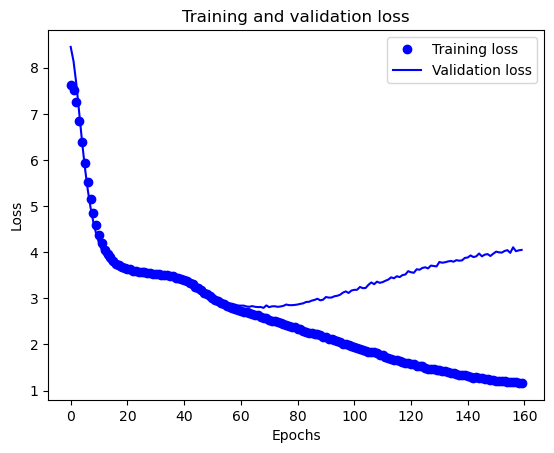

In [175]:
# plt.plot(epochs, history['loss'], 'bo', label='Training loss')
# plt.plot(epochs, history['val_loss'], 'b', label='Validation loss')
plt.plot(range(len(history["loss"])), history['loss'], 'bo', label='Training loss')
plt.plot(range(len(history["loss"])), history['val_loss'], 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

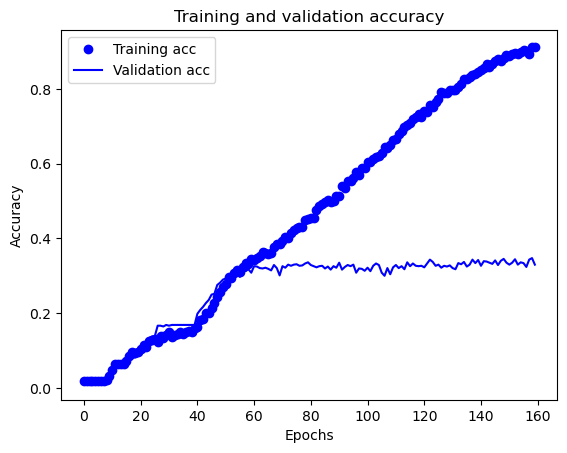

In [176]:
plt.plot(range(len(history["loss"])), history['accuracy'], 'bo', label='Training acc')
plt.plot(range(len(history["loss"])), history['val_accuracy'], 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## Application

In [145]:
def greedy_decode(model, src_seq, max_len):
    src_embs = model.embedding(src_seq)
    memory = model.transformer.encoder(src_embs)
    tgt_seq = torch.LongTensor([token2idx['<s>']]).to(DEVICE)
    tgt_embs = model.embedding(tgt_seq)
    max_len = min(max_len, MAX_LEN)

    for _ in range(max_len-1):
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(
            tgt_embs.size(dim=0), device=device)
        tgt_output = model.transformer.decoder(tgt_embs,
                                               memory,
                                               tgt_mask=tgt_mask)
        char_prob = model.fc(tgt_output[-1])
        next_char = torch.argmax(char_prob)
        tgt_seq = torch.cat(
            (tgt_seq,
             torch.unsqueeze(next_char, dim=0)), dim=0)
        tgt_embs = model.embedding(tgt_seq)
        if next_char.item() == token2idx['</s>']:  
            break
    return tgt_seq[1:]

`greedy_decode` with a batched input: `greedy_decode_batched`

In [146]:
def greedy_decode_batched(model, src_seq, max_len):
    src_seq = src_seq.unsqueeze(0) if src_seq.dim() == 1 else src_seq
    src_embs = model.embedding(src_seq)
    memory = model.transformer.encoder(src_embs)
    tgt_seq = torch.LongTensor([[token2idx['<s>']]]).to(DEVICE)
    tgt_embs = model.embedding(tgt_seq)
    max_len = min(max_len, MAX_LEN)

    for _ in range(max_len - 1):
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(
            tgt_embs.size(dim=1), device=device)
        tgt_output = model.transformer.decoder(
            tgt_embs, memory, tgt_mask=tgt_mask)
        char_prob = model.fc(tgt_output[:, -1, :])  
        next_char = torch.argmax(char_prob, dim=-1).unsqueeze(-1)
        tgt_seq = torch.cat((tgt_seq, next_char), dim=1)
        tgt_embs = model.embedding(tgt_seq)
        if next_char.item() == token2idx['</s>']:
            break
    return tgt_seq[0, 1:]

In [147]:
def translate(model, src_sentence, batched=True):
    model.eval()
    src = seqs2tensors([src_sentence.strip()], token2idx)[0].to(DEVICE)
    num_chars = src.size(dim=0)
    if batched:
        tgt_chars = greedy_decode_batched(
            model, src, max_len=num_chars + 20)
    else:
        tgt_chars = greedy_decode(
            model, src, max_len=num_chars + 20)
    tgt_chars = tensors2seqs([tgt_chars], idx2token)[0]
    if tgt_chars[-1] == '</s>':
        tgt_chars = tgt_chars[:-1]
    tgt_str = ''.join(tgt_chars)
    return tgt_str

In [191]:
tgt_sent = translate(translator, "OJ OJ nu börjar jag bli rätt vilsen här jag fattar inte nånting egentligen", batched=False)
tgt_sent

'They cau there ames aton whime this thime fforyor pe yor your ced.'

In [149]:
tgt_sent = translate(
    translator, "Aujourd'hui, il fait beau. J'irai me baigner à la plage.", batched=False)
tgt_sent

'The ome are are ome ayou athe ome ou ou.'

In [150]:
tgt_sent = translate(translator, "Redkalösköldsfklöte !", batched=False)
tgt_sent

'The atom at tout fo is fout.'

In [193]:
tgt_sent = translate(translator, "ನಾವು ಒಳಗಡೆ ಹೋಹುದಾ?", batched=False)
tgt_sent

'What the do shoghat the?'

## Save model

In [151]:
torch.save(translator.state_dict(), MODEL_NAME)

In [152]:
with open('pico_translator.vocab', 'w') as f:
    json.dump(token2idx, f)

## Evaluate the Model

In [153]:
model = Translator(d_model=D_MODEL,
                   nhead=NHEAD,
                   num_decoder_layers=NUM_ENCODER_LAYERS,
                   num_encoder_layers=NUM_DECODER_LAYERS,
                   dim_feedforward=DIM_FF,
                   vocab_size=VOCAB_SIZE,
                   max_len=MAX_LEN)

In [154]:
model.load_state_dict(torch.load(MODEL_NAME))

<All keys matched successfully>

In [155]:
model.eval()

Translator(
  (embedding): Embedding(
    (input_embedding): Embedding(122, 512, padding_idx=0)
    (pos_embedding): Embedding(122, 512)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-2): 3 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
          )
          (linear1): Linear(in_features=512, out_features=2048, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=2048, out_features=512, bias=True)
          (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.1, inplace=False)
          (dropout2): Dropout(p=0.1, inplace=False)
        )
      )
      (norm): LayerNorm((512,), eps=1e-05, elementw

In [156]:
model.state_dict()

OrderedDict([('embedding.input_embedding.weight',
              tensor([[ 0.0089,  0.0436,  0.0910,  ..., -0.0577, -0.0271,  0.0746],
                      [-0.0734,  0.0246, -0.0842,  ...,  0.0826,  0.0401,  0.0455],
                      [ 0.0063,  0.0130,  0.0930,  ...,  0.0638,  0.0226, -0.0865],
                      ...,
                      [ 0.0505, -0.0687, -0.0728,  ..., -0.0138,  0.0791, -0.0699],
                      [ 0.0691, -0.0741,  0.0952,  ..., -0.0657, -0.0951, -0.0660],
                      [ 0.0226, -0.0650, -0.0138,  ...,  0.0234, -0.0727,  0.0698]])),
             ('embedding.pos_embedding.weight',
              tensor([[ 0.0000e+00,  1.0000e+00,  0.0000e+00,  ...,  1.0000e+00,
                        0.0000e+00,  1.0000e+00],
                      [ 8.4147e-01,  5.4030e-01,  8.2186e-01,  ...,  1.0000e+00,
                        1.0366e-04,  1.0000e+00],
                      [ 9.0930e-01, -4.1615e-01,  9.3641e-01,  ...,  1.0000e+00,
                        2

In [157]:
model = model.to(DEVICE)

In [170]:
translate(model, "ingmar")

'The aus ooome anom.'

In [159]:
cand = []
for i, seq in tqdm(enumerate(val_src_seqs)):
    cand.append(translate(model, seq.strip()))
# cand

32it [00:18,  1.69it/s]


In [160]:
bleu_score(cand, val_tgt_seqs)

tensor(0.)